# AI Cohort Beginner Project

## Description

This project has the objective of demonstrating the topics and skills learned from the AI Cohort Beginner Level courses. The problem selected for this project was the one presented by the [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data) Kaggle dataset.

Churn: a regular, quantifiable process or rate of change that occurs in a business over a period of time as existing customers are lost and new customers are added

The objective of this notebook is to build three models and compare their performance in their ability to predict customer churn. The three models, a logistic regression, a neural network and a decision tree will be compared using classification metrics, and a final model will be selected to analyze its business impact, in this case, Telco. 






## Explore and Clean Dataset

In [1]:
import pandas as pd
import numpy as np

In [2]:
pd.set_option('display.max_columns', None)
dataset = pd.read_csv('../data/Telco-Customer-Churn.csv')

In [3]:
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
dataset.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [5]:
#Verify if there are missing values
dataset.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
#Drop unique ID column
dataset = dataset.drop('customerID', axis=1)

In [7]:
#Verify the datatype of each column
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
#TotalCharges column value is of type str but represents a numerical value. Convert from str to float.
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [9]:
#blank strings were forced to convert to NaN.
dataset.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [10]:
#To address NaN values, will update NaN values to 0
#Explore examples with NaN values in TotalCahrges
dataset[dataset['TotalCharges'].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Since all examples with NaN in TotalCharges column have the value 0 in tenure, it means that the persons have not been charged yet since they have not completed a month receiving services from the service provider. We can convert NaN values to 0.

In [11]:
dataset['TotalCharges'] = dataset['TotalCharges'].fillna(0)
dataset.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Categorical Feature Analysis

/var/folders/_x/v31jblm52cq579qc0dzpptzm0000gn/T/ipykernel_82349/3278476386.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = dataset.select_dtypes(include='object').columns.tolist()


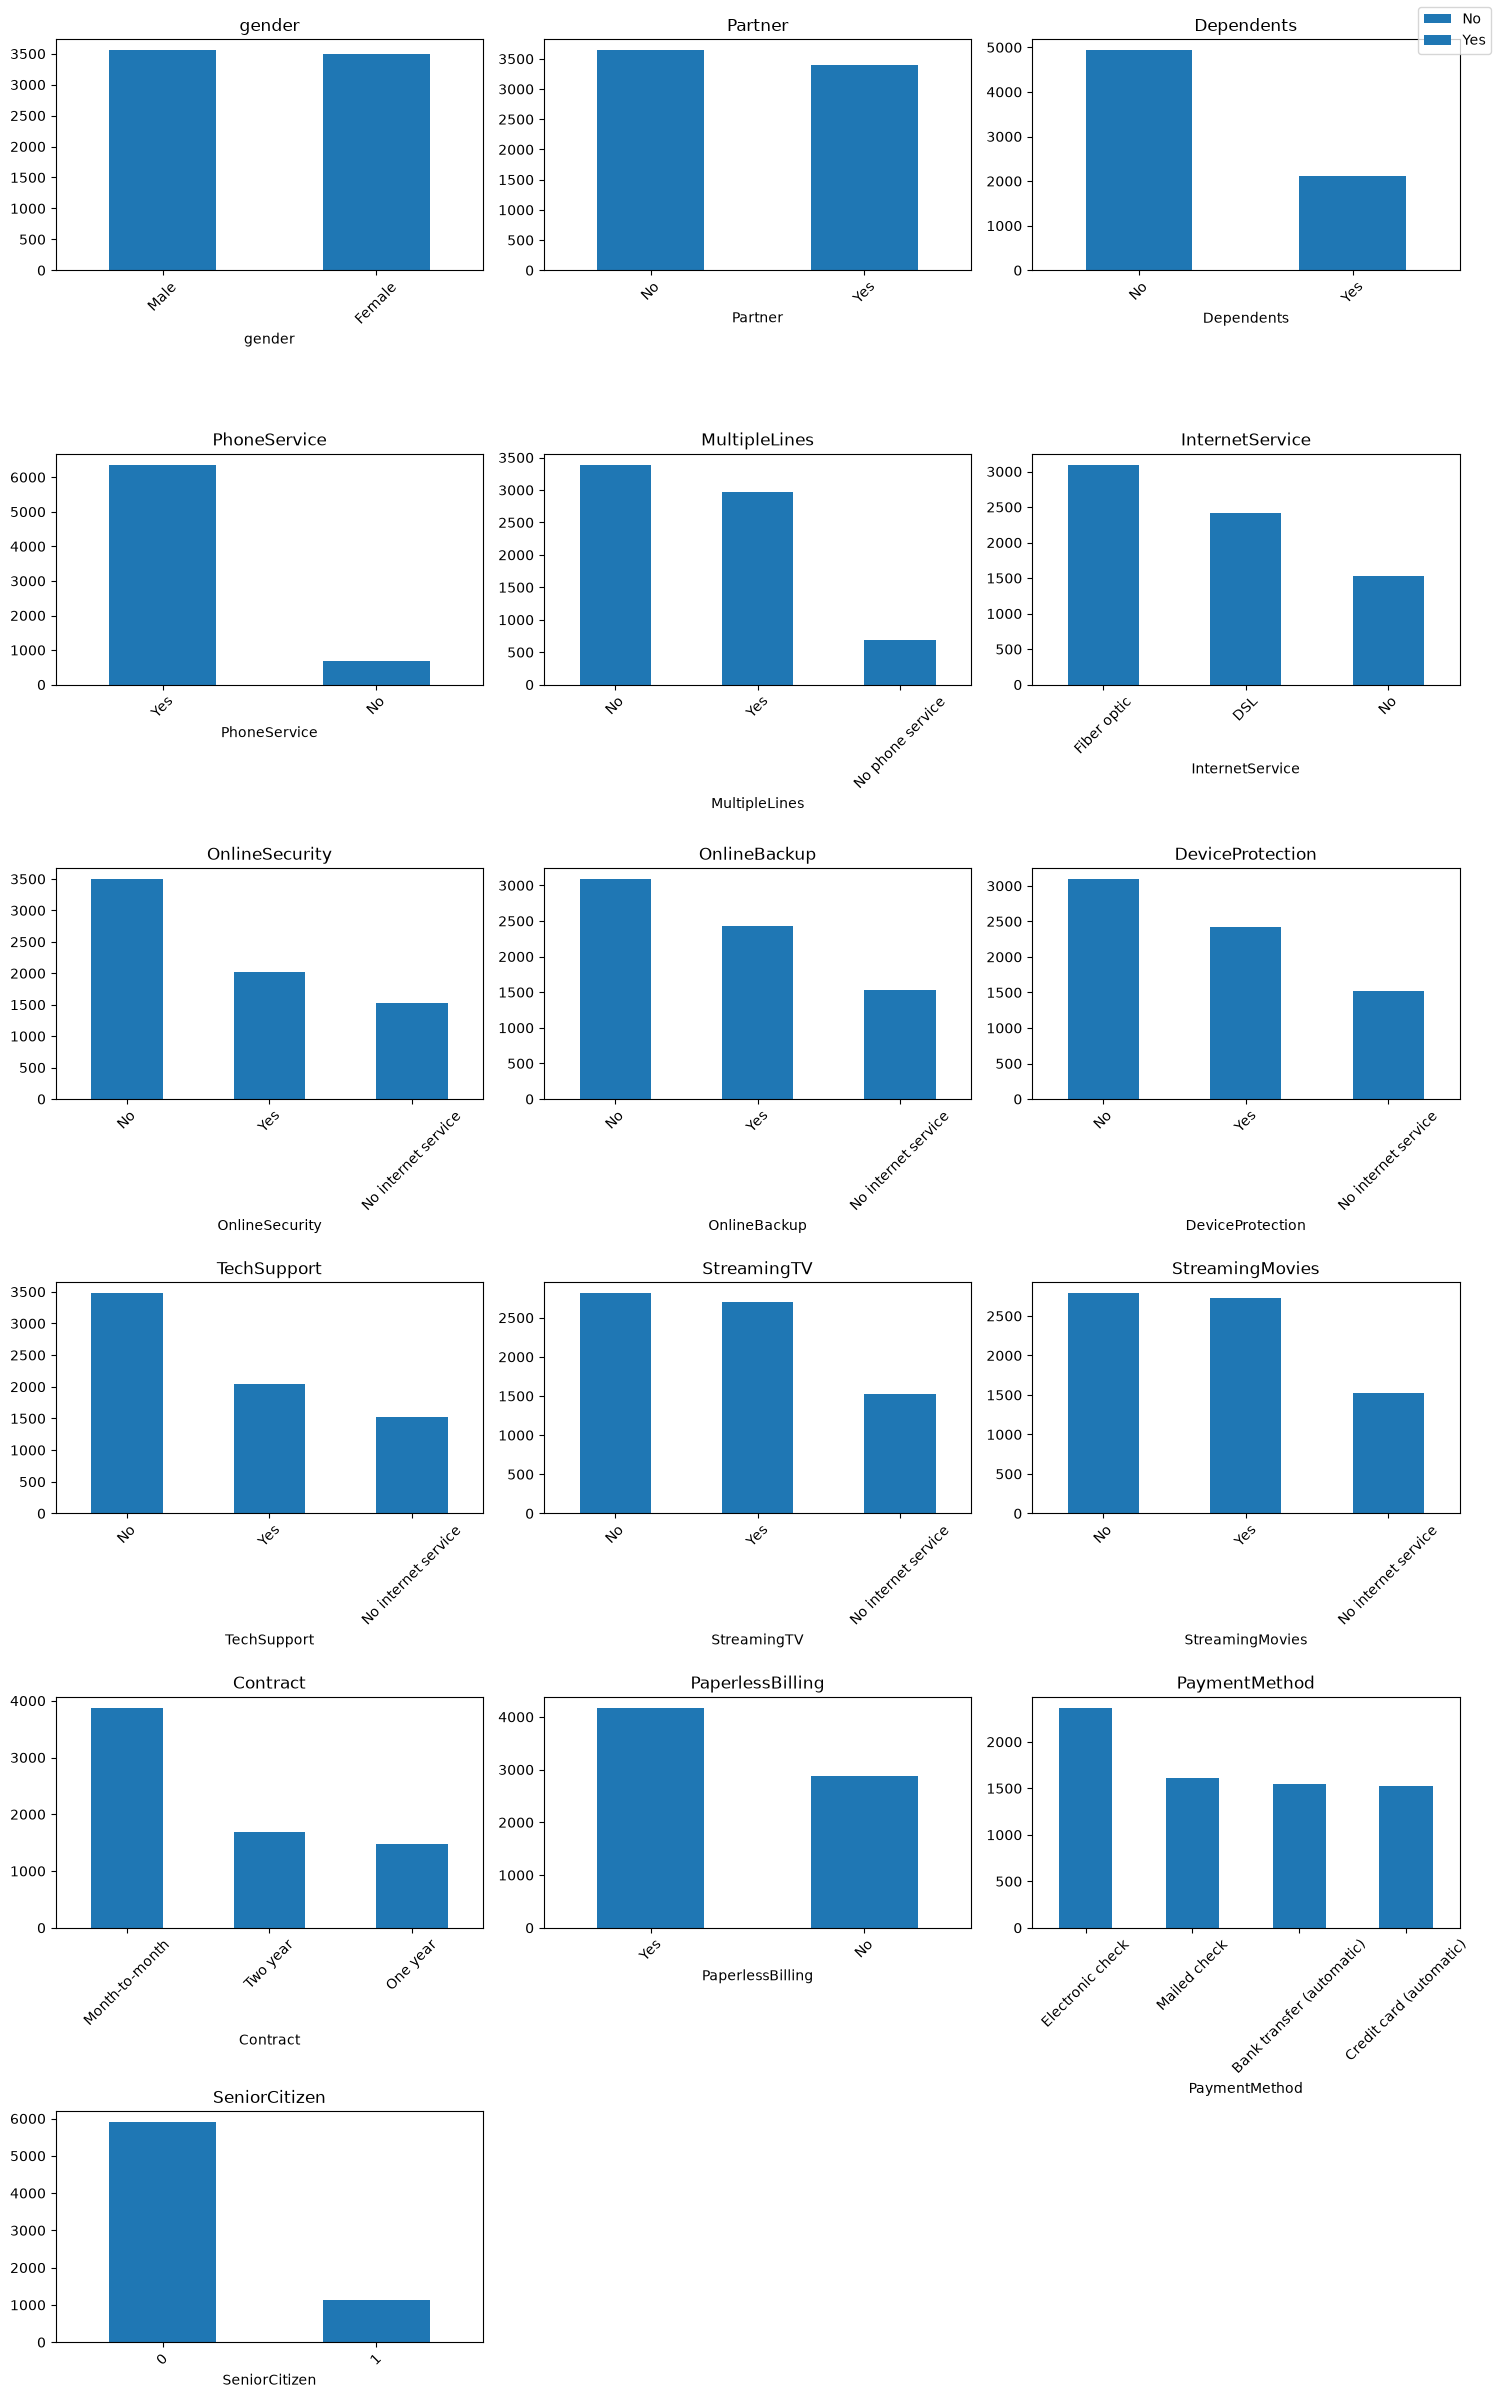

In [12]:
#Independent features analysis
import matplotlib.pyplot as plt
import seaborn as sns
import math

categorical = dataset.select_dtypes(include='object').columns.tolist()
categorical = [col for col in categorical if col != 'Churn']
categorical = categorical + ['SeniorCitizen']



numerical = dataset.select_dtypes(include="number").columns.tolist()
numerical = [col for col in numerical if col != 'SeniorCitizen']

#Plot categorical features with count value
rows = math.ceil(len(categorical) / 3)
fig, axes = plt.subplots(rows, 3, figsize=(5 * 3, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, categorical):
    dataset[col].value_counts().plot(kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categorical):]:
    ax.axis("off")

fig.legend(["No", "Yes"], loc="upper right")
plt.tight_layout()
plt.show()


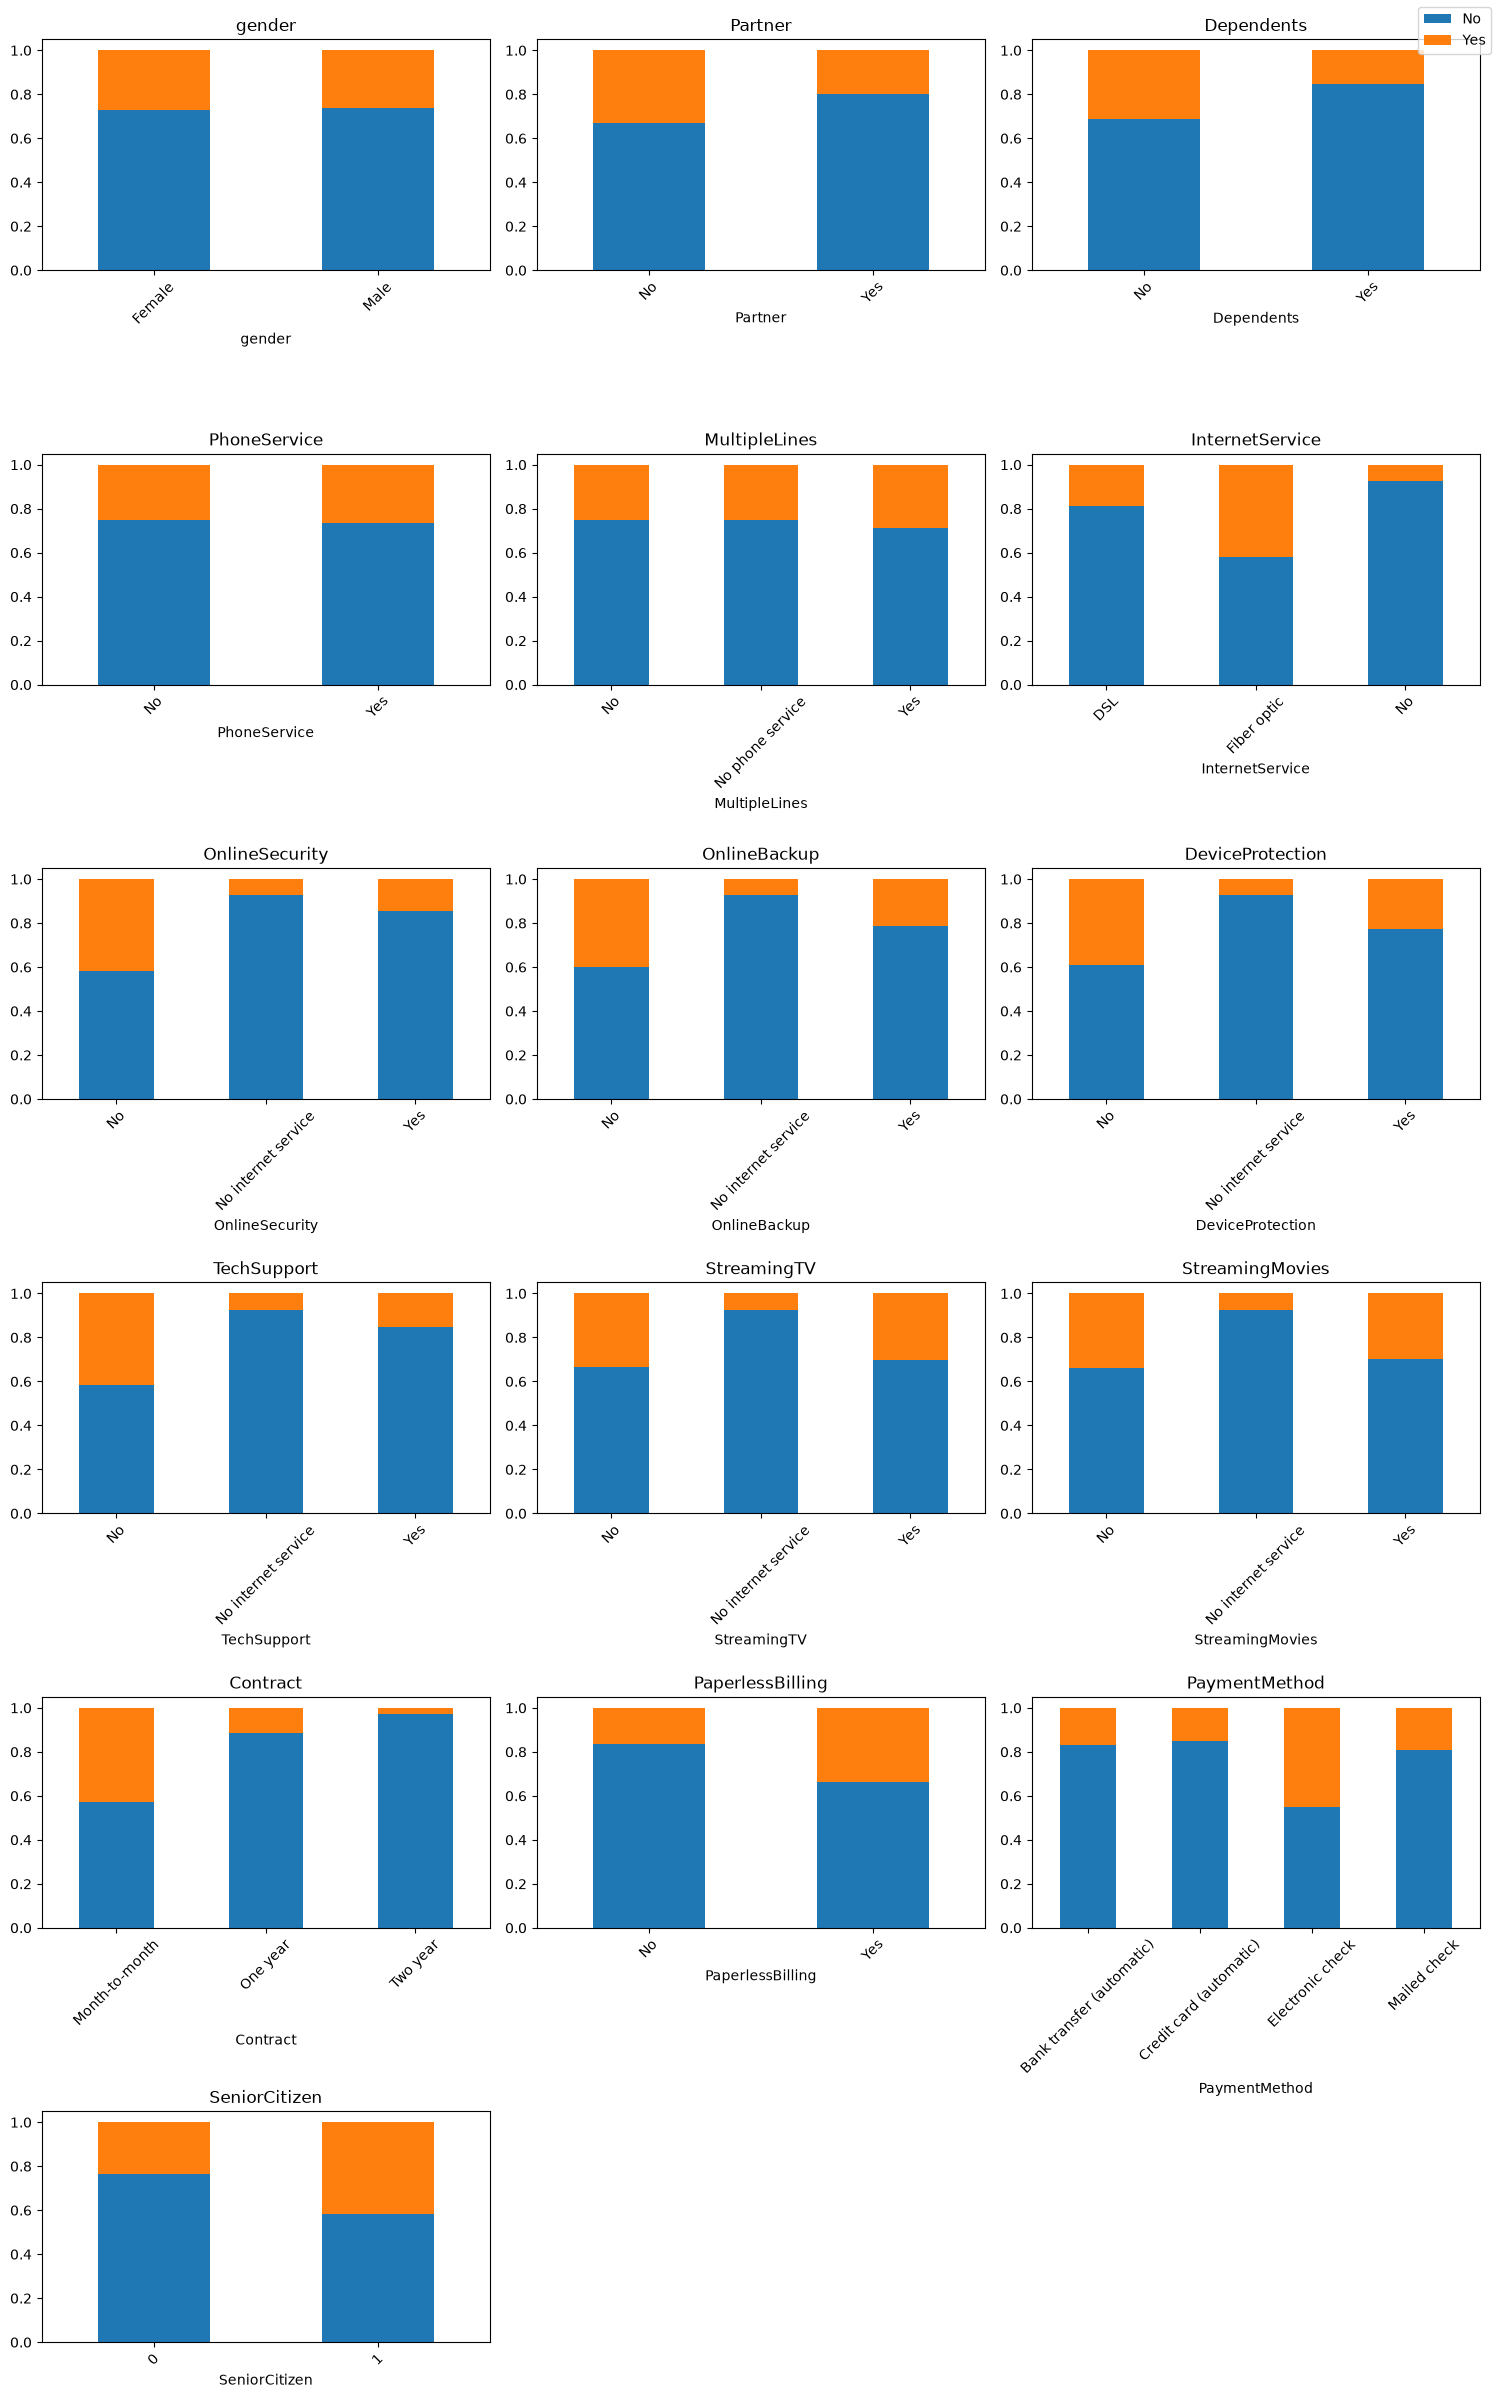

In [13]:
#Plot categorical features churn rate density.

rows = math.ceil(len(categorical) / 3)
fig, axes = plt.subplots(rows, 3, figsize=(5 * 3, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, categorical):
    pd.crosstab(dataset[col], dataset["Churn"], normalize="index").plot(
        kind="bar", stacked=True, ax=ax, legend=False)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(categorical):]:
    ax.axis("off")

fig.legend(["No", "Yes"], loc="upper right")
plt.tight_layout()
plt.show()






The following conclusions can be drawn from the categorical features analysis:
- The majority of contracts are month-to-month contracts and those with a month-to-month contract show a higher churn rate.
- Of those who have internet service, the majority has fiber optic internet, and those with fiber optic internet demonstrate higher churn rate.
- Those that do not have internet service show a lower churn rate than those with internet service.
- Those that do not have Online Security show a higher churn rate than those who do not. The same can be said about those who do not have Online Backup and Device Protection.
- Customers with electronic check as a payment method show a higher churn rate than those that use a different payment method.


## Numerical Features Analysis

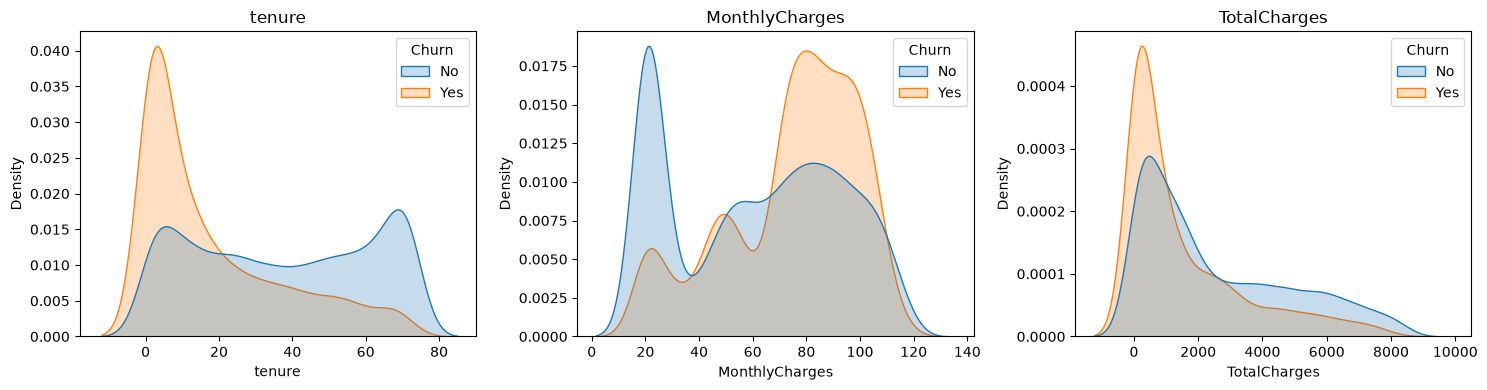

In [14]:
import seaborn as sns

rows = math.ceil(len(numerical) / 3)
fig, axes = plt.subplots(rows, 3, figsize=(5 * 3, 4 * rows))
axes = axes.flatten()

for ax, col in zip(axes, numerical):
    sns.kdeplot(data=dataset, x=col, hue="Churn", common_norm=False, ax=ax, fill=True) #kernel density estimate
    ax.set_title(col)

for ax in axes[len(numerical):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


Tenure, monthly charges and total charges are the only numerical features of the dataset. The above figures demonstrate the density of churn customers of each numerical feature. The following can be inferred:
- Customers with low tenure show a high churn rate than those with longer tenure.
- Churn rate increases as monthly charges increses.

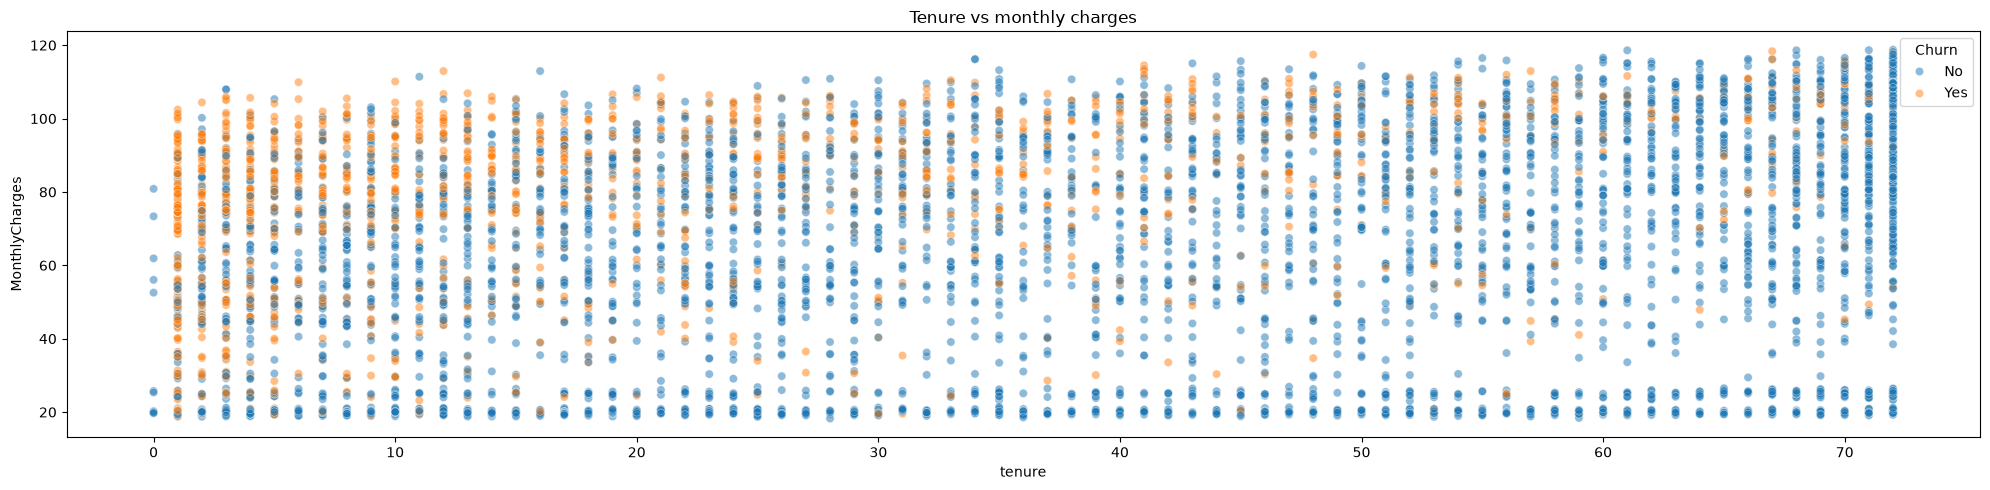

In [15]:
# Distribution of tenure and monthly charges, split by churn

fig, ax = plt.subplots(1, 1, figsize=(20,5))

# Scatter plot showing relation between tenure, monthly charges and churn
sns.scatterplot(data=dataset, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.5, ax=ax)
ax.set_title("Tenure vs monthly charges")


plt.tight_layout()
plt.show()

The figure shows the relation between tenure, monthly charges and churn. It can be inferred that customers with lower tenure and higher monthly charges show a higher churn rate.

### Hot-one-encode categorical data

In [16]:
#Create a list of categorical data to give to get_dummies() pandas function.
#Encode binary features to 1 and 0
categorical_features = ['MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaymentMethod']
binary_features = ['Partner','Dependents','PhoneService','PaperlessBilling','Churn']

for feature in binary_features:
    dataset[feature] = dataset[feature].map({'Yes': 1, 'No': 0})

dataset['gender'] = dataset['gender'].map({'Male': 1, 'Female': 0})


In [17]:
print(f'Dataset shape before one-hot-encoding categorical features: {dataset.shape}')

dataset = pd.get_dummies(dataset, columns=categorical_features, dtype=int)

print(f'Dataset shape after one-hot-encoding categorical features {dataset.shape}')


Dataset shape before one-hot-encoding categorical features: (7043, 20)
Dataset shape after one-hot-encoding categorical features (7043, 41)


In [18]:
#Separate dataset into features and label
y = dataset['Churn']
X = dataset.drop('Churn', axis=1)
print(y.shape)
#print(y_dt.shape)
print(X.shape)
#print(X_dt.shape)

(7043,)
(7043, 40)


In [19]:
#For a classification dataset, verify how balanced is the target data. How many 1 and 0. 
#This can show if dataset is skewed and thus helps select which evaluation metric use (Accuracy, Recall, Recision, etc)
y.value_counts().loc[[0, 1]]

Churn
0    5174
1    1869
Name: count, dtype: int64

The label data is skewed since approximately 74.5% of labels are No-Churn and 25.5% is Churn. 

In [20]:
#Split data to use on all models
from sklearn.model_selection import train_test_split
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.3, random_state=3, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_, y_, test_size=0.5, random_state=3, stratify=y_)


print(f'Shape of training dataset: {X_train.shape}')
print(f'Shape of validation dataset: {X_val.shape}')
print(f'Shape of test dataset: {X_test.shape}')
print(f'Shape of the training target values: {y_train.shape}')
print(f'Shape of the validation target values: {y_val.shape}')
print(f'Shape of the test target values: {y_test.shape}')



Shape of training dataset: (4930, 40)
Shape of validation dataset: (1056, 40)
Shape of test dataset: (1057, 40)
Shape of the training target values: (4930,)
Shape of the validation target values: (1056,)
Shape of the test target values: (1057,)


## Logistic Regression
A logistic regression model will be built to measure its performance on the dataset and serve as a reference to measure more complex models, such as the neural network and decision tree models.

In [21]:
#Create a linear regression model as a base modelfrom sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

#Used StandardScaler to scale all features

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train, )
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


              precision    recall  f1-score   support

           0       0.91      0.77      0.83       776
           1       0.55      0.79      0.65       281

    accuracy                           0.77      1057
   macro avg       0.73      0.78      0.74      1057
weighted avg       0.81      0.77      0.78      1057



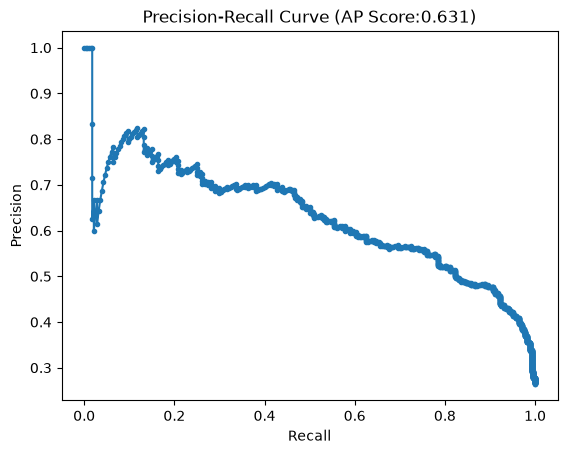

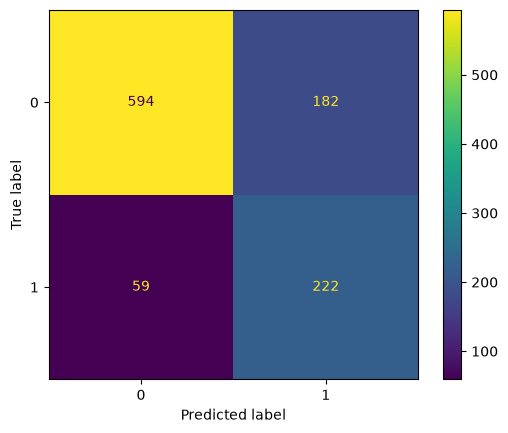

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report, ConfusionMatrixDisplay

#Lets build a simple regression model to serve as a baseline 

logistic = LogisticRegression(class_weight="balanced", random_state=3)
logistic.fit(X_train_scaled, y_train)

val_prob = logistic.predict_proba(X_val_scaled)[:,1]

ap_score = average_precision_score(y_val, val_prob)

#Precision-Recall curve values
prec, rec, thr = precision_recall_curve(y_val, val_prob)

#Find threshold that maximizes F1 Score
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1)]

test_proba = logistic.predict_proba(X_test_scaled)[:,1]
test_pred = (test_proba >= best_thr).astype(int)
print(classification_report(y_test, test_pred))

#Plot PR Curve
plt.plot(rec, prec, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AP Score:{ap_score:.3f})')
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.show()

## Neural Network Model

In [23]:
#Create model arquitecture
from tensorflow.keras.utils import set_random_seed
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy
from tensorflow.keras.callbacks import EarlyStopping

set_random_seed(42)

#Since there are 40 input features, model1 creates an input neuron for each input feature.
model1 = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model1.compile(optimizer='adam', loss=BinaryCrossentropy())

#Defining an early stopping callback to use for all models
callback = EarlyStopping(patience=10, restore_best_weights=True)



In [24]:
#Train model 
history1 = model1.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback]
)

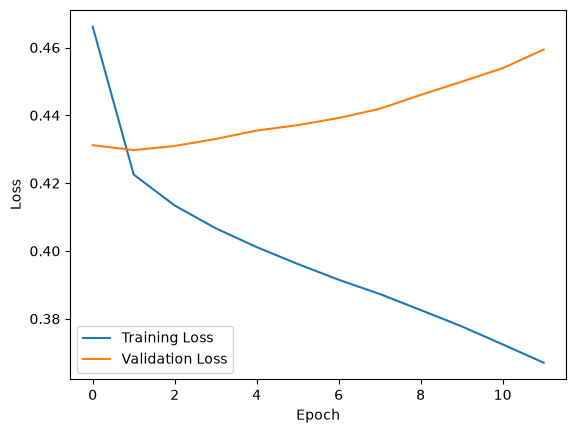

In [25]:
plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

As training loss decreases the validation loss increases, this is a case of overfitting. A less complex model will be tried.

In [26]:
#Try a less complex neural netowrk. Can help for overfitting.

model2 = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model2.compile(optimizer='adam', loss=BinaryCrossentropy())

callback2 = EarlyStopping(patience=10, restore_best_weights=True)
#Train model 
history2 = model2.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback2]
)
callback2 = EarlyStopping(patience=10, restore_best_weights=True)




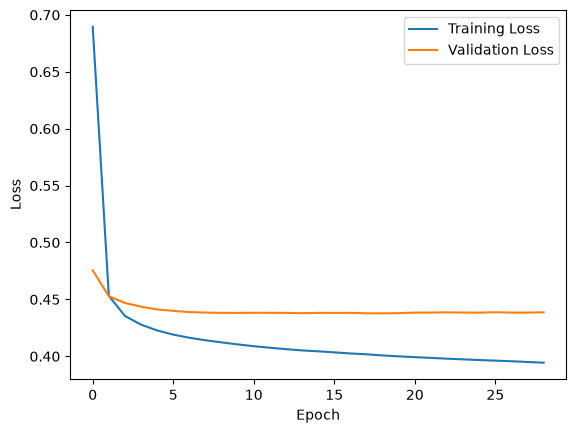

In [27]:
#Plot history for model2
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model2 show improvement on high variance as it stabilizes and seems to converge to a number. Let's decrease model architecture complex even more.

In [28]:
model3 = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model3.compile(optimizer='adam', loss=BinaryCrossentropy())
callback3 = EarlyStopping(patience=10, restore_best_weights=True)

#Train model 
history3 = model3.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback3]
)

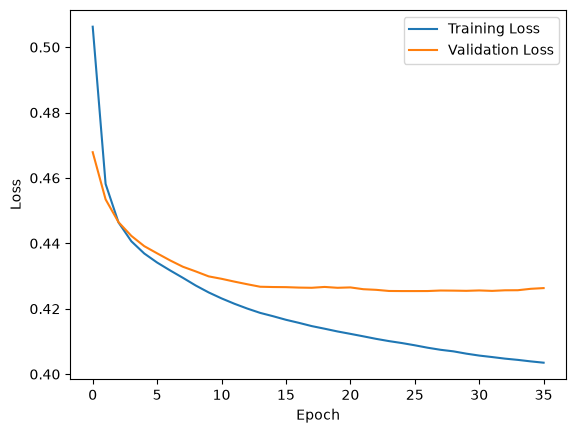

In [29]:
plt.plot(history3.history['loss'], label='Training Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model3 seems to overfitt as epochs increases. Lets plot all three models with respect to the validation loss.

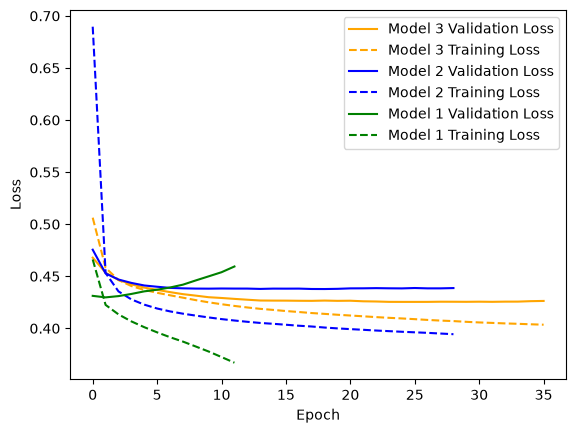

In [30]:
plt.plot(history3.history['val_loss'], label='Model 3 Validation Loss', color='orange')
plt.plot(history3.history['loss'], label='Model 3 Training Loss', linestyle='--', color='orange')
plt.plot(history2.history['val_loss'], label='Model 2 Validation Loss', color='blue')
plt.plot(history2.history['loss'], label='Model 2 Training Loss', linestyle='--', color='blue')
plt.plot(history1.history['val_loss'], label='Model 1 Validation Loss', color='green')
plt.plot(history1.history['loss'], label='Model 1 Training Loss', linestyle='--', color='green')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

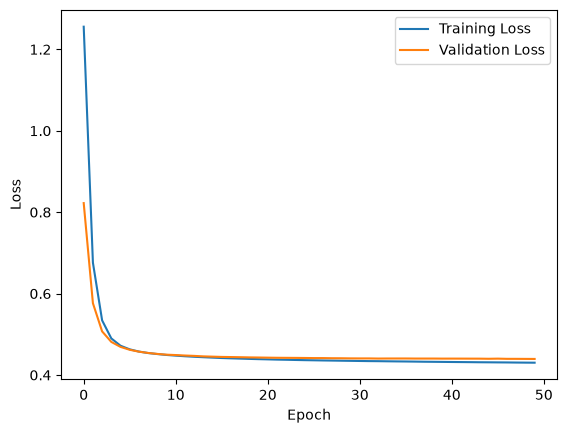

In [31]:
#Apply regularization for model1, model2 and model3
from tensorflow.keras.regularizers import l2

model1_r = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model1_r.compile(optimizer='adam', loss=BinaryCrossentropy())
callback1r = EarlyStopping(patience=10, restore_best_weights=True)

history1_r =  model1_r.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback1r]
)

best_loss_m1r = callback1r.best
plt.plot(history1_r.history['loss'], label='Training Loss')
plt.plot(history1_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


When applying regularization, model1 stabilizes and its loss converges. Let's apply regularizqtion to model2.

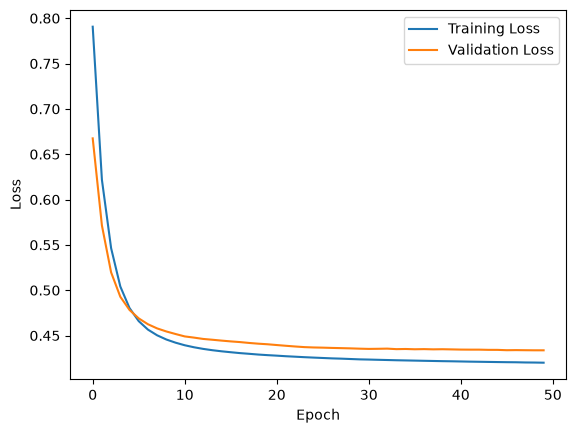

In [32]:
model2_r = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model2_r.compile(optimizer='adam', loss=BinaryCrossentropy())
callback2r = EarlyStopping(patience=10, restore_best_weights=True)

#Train model 
history2_r = model2_r.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback2r]
)

best_loss_m2r = callback2r.best

plt.plot(history2_r.history['loss'], label='Training Loss')
plt.plot(history2_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model2 with regularization improves as well.

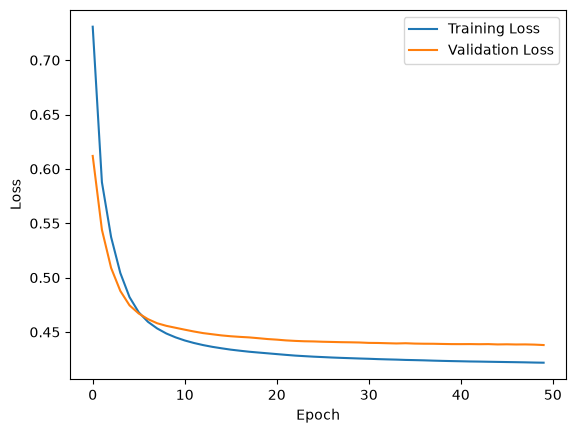

In [33]:
model3_r = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(4, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model3_r.compile(optimizer='adam', loss=BinaryCrossentropy())
callback3r = EarlyStopping(patience=10, restore_best_weights=True)

#Train model 
history3_r = model3_r.fit(
    X_train_scaled, y_train, 
    validation_data=(X_val_scaled, y_val),
    epochs=50, verbose=0, callbacks=[callback3r]
)

best_loss_m3r = callback3r.best

plt.plot(history3_r.history['loss'], label='Training Loss')
plt.plot(history3_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


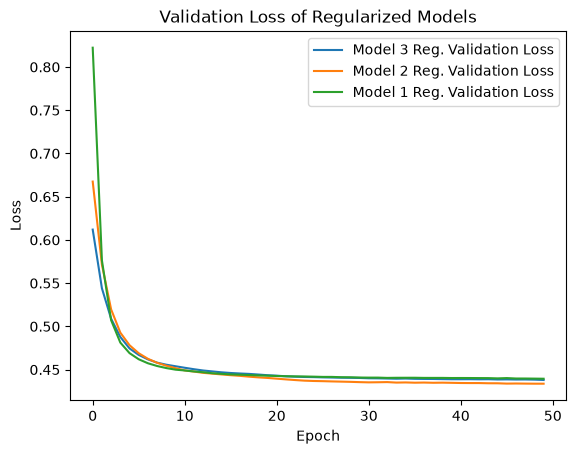

In [34]:
#Plot all three regularized model's validation loss
plt.plot(history3_r.history['val_loss'], label='Model 3 Reg. Validation Loss')
plt.plot(history2_r.history['val_loss'], label='Model 2 Reg. Validation Loss')
plt.plot(history1_r.history['val_loss'], label='Model 1 Reg. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title("Validation Loss of Regularized Models")
plt.legend()
plt.show()

The above figure compares all 3 regularized models with respect to the validation loss value. The difference between the models is small with model 2 with regularization presenting the lesser value.

model2_r: loss=0.4337
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 435us/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 864us/step
              precision    recall  f1-score   support

           0       0.90      0.75      0.82       776
           1       0.53      0.78      0.63       281

    accuracy                           0.75      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.75      0.77      1057



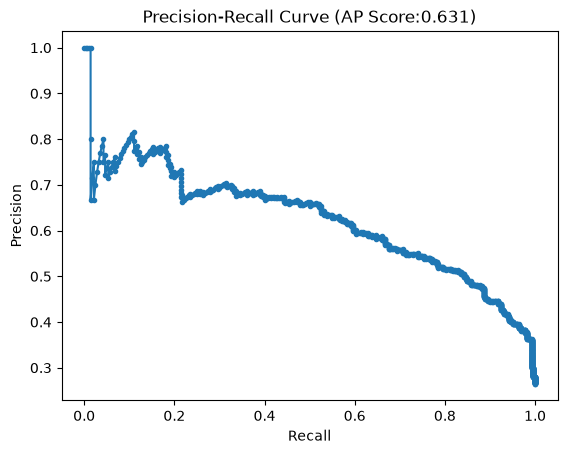

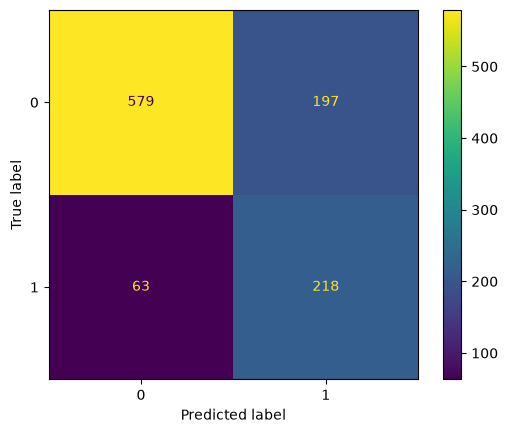

In [35]:
#Evaluate model2_r on validation data
loss = model2_r.evaluate(X_val_scaled, y_val, verbose=0)
print(f"model2_r: loss={loss:.4f}")

#numpy array of predictions
proba = model2_r.predict(X_val_scaled)

#precision_recall_curve
prec, rec, thr = precision_recall_curve(y_val, proba)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = thr[np.argmax(f1)]

test_proba = model2_r.predict(X_test_scaled)
test_pred = (test_proba >= best_thr).astype(int)

print(classification_report(y_test, test_pred))

#Plot PR Curve
plt.plot(rec, prec, marker='.')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'Precision-Recall Curve (AP Score:{ap_score:.3f})')
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.show()

## Decision Tree Model
Decision trees are another machiner learning algorithm that can be used for regression and classification problems. The CatBoost decision tree algorithm will be used to try and improve prediction metrics from the previous neural network and logistic regression models. 
Catboost advantages:
- Does not requires categorical features to be one-hot-encoded.
- Handles NaN values
- Has a built-in grid search for parameter tuning.

In [36]:
#Load Data
df = pd.read_csv('../data/Telco-Customer-Churn.csv')
X = df.drop(['Churn', 'customerID'], axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
X['TotalCharges'] = X['TotalCharges'].fillna(0)


X_train_dt,X_, y_train_dt, y_ = train_test_split(X,y, test_size=0.3, random_state=3, stratify=y)
X_val_dt, X_test_dt, y_val_dt, y_test_dt = train_test_split(X_,y_, test_size=0.5, random_state=3, stratify=y_)

In [37]:
#Need to pass to catboost a list of categorical features
categorical = X_train_dt.select_dtypes(include='object').columns.tolist()
categorical

/var/folders/_x/v31jblm52cq579qc0dzpptzm0000gn/T/ipykernel_82349/2307835278.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_train_dt.select_dtypes(include='object').columns.tolist()


['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [38]:
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    log_loss,
    precision_recall_curve,
)

#Use Pool to wrap datasets
train_pool = Pool(X_train_dt, y_train_dt, cat_features=categorical)
val_pool = Pool(X_val_dt, y_val_dt, cat_features=categorical)
test_pool = Pool(X_test_dt, y_test_dt, cat_features=categorical)

#Created a base model for grid_search
base_model = CatBoostClassifier(
    eval_metric='PRAUC',
    learning_rate=0.1,
    random_seed=3,
    logging_level='Silent',
    auto_class_weights='Balanced',
    thread_count=-1
)

#List of variables to test models on
param_grid = {
    "depth": [4, 6, 8],
    "l2_leaf_reg": [10, 30, 100, 300],
}


grid_result_base_model = base_model.grid_search(
    param_grid,
    X=train_pool,
    cv=5,
    partition_random_seed=3,
    search_by_train_test_split=False,
    verbose=False,
    refit=False
)

print(grid_result_base_model['params'])



{'depth': 4, 'l2_leaf_reg': 300}


Best Threshold: 0.4690322245415436



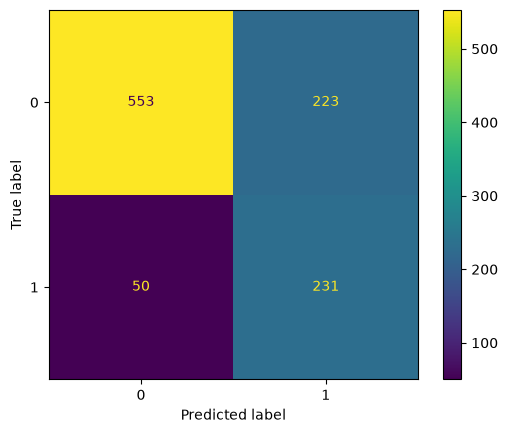

              precision    recall  f1-score   support

           0       0.92      0.71      0.80       776
           1       0.51      0.82      0.63       281

    accuracy                           0.74      1057
   macro avg       0.71      0.77      0.72      1057
weighted avg       0.81      0.74      0.76      1057



In [39]:
# Use best params for final catboost model.
catboost = CatBoostClassifier(
    **base_model.get_params(), 
    **grid_result_base_model['params'],
    early_stopping_rounds=100,
)

catboost.fit(train_pool, eval_set=val_pool, use_best_model=True)
 
 
#Test on validation data
val_proba = catboost.predict_proba(val_pool)[:, 1]


prec, rec, thr = precision_recall_curve(y_val_dt, val_proba)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
dt_best_thr = thr[np.argmax(f1)]

#Apply best threshold to classification predictions
test_proba = catboost.predict_proba(test_pool)[:, 1]
test_pred = (test_proba >= dt_best_thr).astype(int)
print(f"Best Threshold: {dt_best_thr}\n")

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test_dt, test_pred)
plt.show()

print(classification_report(y_test_dt, test_pred))


## Models Comparison

Comparison of the quality of the classification models will be done using the Average Precision score. The Average Precision score measures the model's ability to balance precision and recall across all thresholds. It is useful when the objective of the model is to a class from an imbalanced dataset. The scikit learn average precision score implementation will be used for the models evaluation.

In [40]:
lg_proba = logistic.predict_proba(X_test_scaled)[:,1]
nn_proba = model2_r.predict(X_test_scaled)
cb_proba = catboost.predict_proba(test_pool)[:, 1]

lg_ap_score = average_precision_score(y_test, lg_proba)
nn_ap_score = average_precision_score(y_test, nn_proba)
cb_ap_score = average_precision_score(y_test_dt, cb_proba)


print(f'LogisticRegression Avg Precision Score:{lg_ap_score:.3f}')
print(f'Neural Network Avg Precision Score:{nn_ap_score:.3f}')
print(f'CatBoost Avg Precision Score:{cb_ap_score:.3f}')

34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 501us/step
LogisticRegression Avg Precision Score:0.657
Neural Network Avg Precision Score:0.667
CatBoost Avg Precision Score:0.686


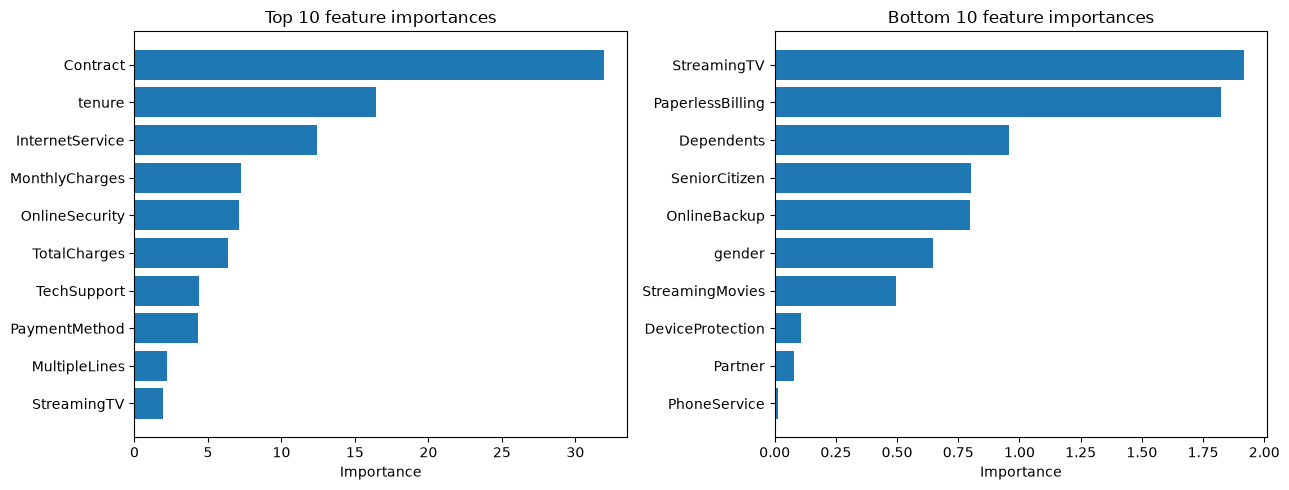

In [41]:
#Plot Feature importance
importances = catboost.get_feature_importance(prettified=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Plot most important features
ax1.barh(importances['Feature Id'][:10], importances['Importances'][:10])
ax1.invert_yaxis()
ax1.set_title("Top 10 feature importances")
ax1.set_xlabel("Importance")

# Plot least important features
ax2.barh(importances['Feature Id'][-10:], importances['Importances'][-10:])
ax2.invert_yaxis()
ax2.set_title("Bottom 10 feature importances")
ax2.set_xlabel("Importance")

plt.tight_layout() 

CatBoost default feature importance values is the PredictionValuesChange value. For each feature, PredictionValuesChange shows how much on average the prediction changes if the feature value changes. The bigger the value of the importance the bigger on average is the change to the prediction value, if this feature is changed.

From the above figure, the CatBoost model shows that the top most important features are MonthlyCharges, Contract and tenure, meaning that those features have a stronger impact in shifting the model's output. 

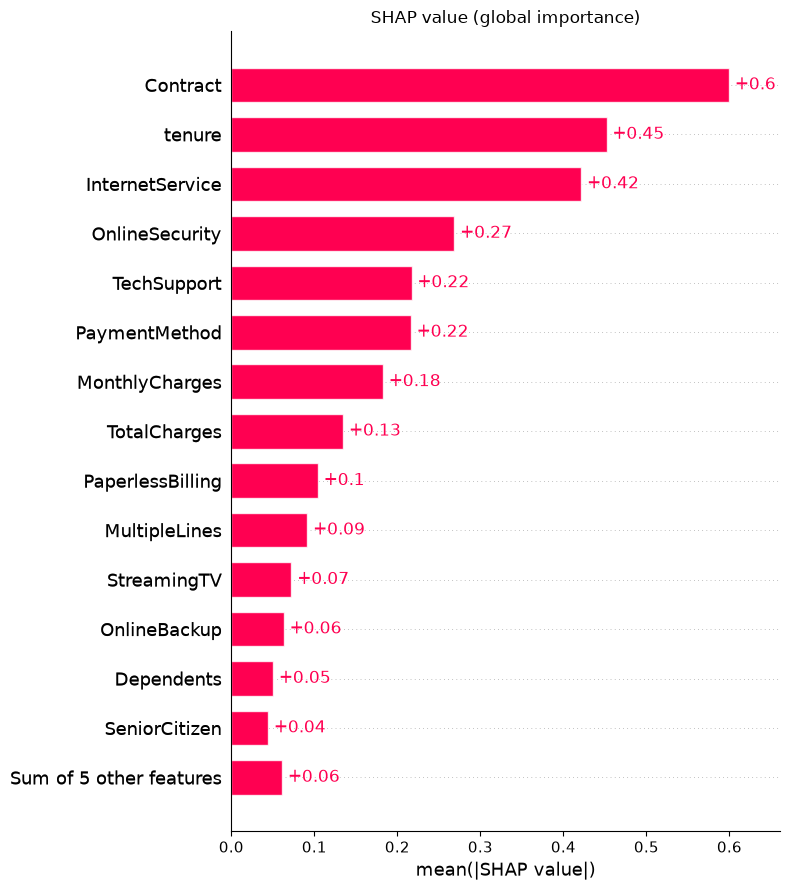

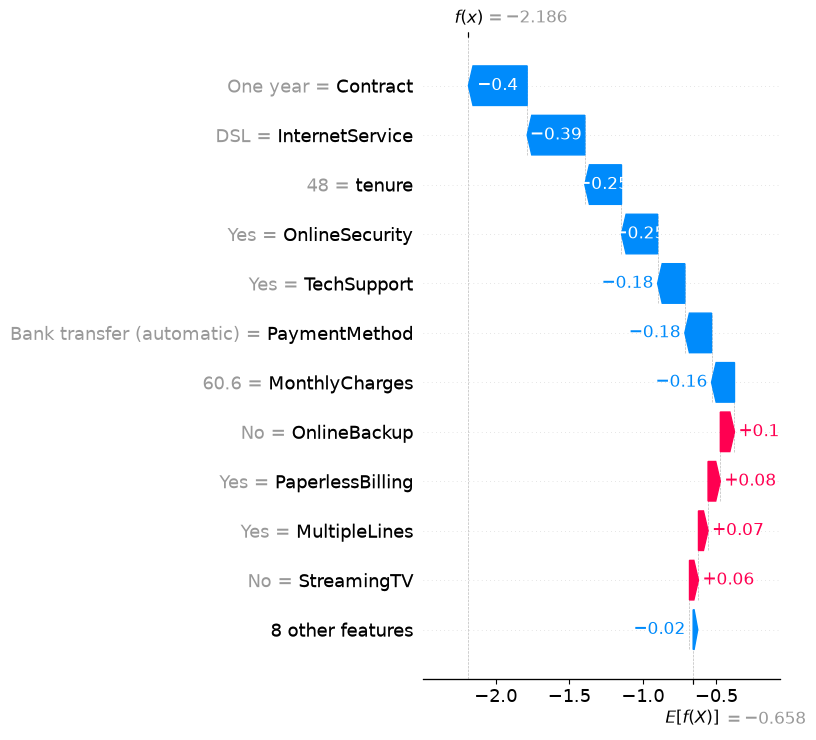

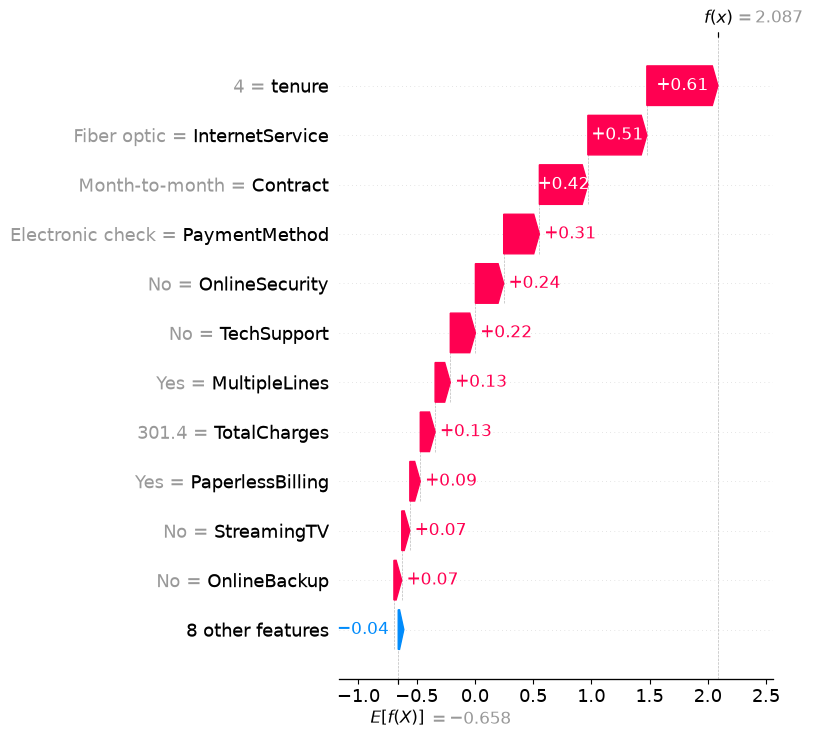

In [42]:
#SHAP Values
import shap
explainer = shap.TreeExplainer(catboost)
shap_values = explainer.shap_values(test_pool)    
base_value = explainer.expected_value              
 
X_numeric = X_test_dt.copy()
for col in categorical:
    X_numeric[col] = X_numeric[col].astype("category").cat.codes
 
exp_raw = shap.Explanation(
    values=shap_values, base_values=np.repeat(base_value, len(X_test_dt)),
    data=X_test_dt.values, feature_names=list(X_test_dt.columns),
)
# Global importance
# Average absolute SHAP value per feature.
shap.plots.bar(exp_raw, max_display=15, show=False)
plt.title("SHAP value (global importance)")
plt.tight_layout()
plt.show()
 
#No-Churn Customer
i = 0
shap.plots.waterfall(exp_raw[i], max_display=12, show=False)
plt.tight_layout()
plt.show()

#Churn Customer
i = 5
shap.plots.waterfall(exp_raw[i], max_display=12, show=False)
plt.tight_layout()
plt.show()



SHAP values measure the impact of each feature in the models prediction. The difference between SHAP and PredictionValuesChange is that PredictionValuesChange informs how much does a feature matters, but not in which direction, whereas the SHAP values tells how much a feature pushes the prediction towards a direction, in this case CHurn or No-Churn.

SHAP values are displayed as log-odds. To convert the model probabilities to log-odds, the following formula is used:

logit(p) = ln(p / (1 − p))

If we use the formula to convert the best threshold, which is 0.5368, we get the value of 0.147. Thus a customer needs to get a SHAP value summation of >= 0.147 to get classification of Churner.

The waterfall plot starts at E[f(X)] = −0.567 which is the model’s average output. Each bar shows how much one feature moved the prediction away from the average. For this customer, the model outputs a SHAP value of -2.182. A one-year contract, lower monthly charges, and a tenure of 48 months were the strongest reasons this customer was predicted as a No-Churn, since its SHAP value sits below the threshold of 0.147.

In the second waterfall example, the model outputs a SHAP value of 1.949, which is greater than the threshold, thus this customer was classified as a Churn. A lower contract, lower tenure, no technical support and high monthly charges pushed the prediction towards a churner customer.





## Conclusion
Three models were compared for predicting Telco customer churn: logistic regression, a neural network, and CatBoost. All performed similarly (AP 0.625–0.648), with CatBoost slightly ahead. CatBoost is selected because it delivers the best average precision, requires minimal preprocessing, and provides SHAP-based explanations that identify why each customer is at risk. The main churn drivers are month-to-month contracts, short tenure, high monthly charges, and missing tech support or security add-ons. The business should identify actions to target churn customers based on the most important features, examples being offering contract discounts, bundled support services and researching their fiber optic service quality. Because the model’s advantage over logistic regression is small, further validation such as cross-validation and cost-based threshold tuning should be performed before deployment. 